**AICE Associate <font color=red>실전 모의고사 (문제)</font>** — AICE_Asso_006_실전형_회귀_물류배송지연예측

### **배송 건 데이터를 활용한 <span style="color:darkgreen">총 배송 소요시간(시간)</span> 예측**
---

- 도메인 : 물류 배송 지연 예측
- 목  표 : 총 배송 소요시간(시간)을 예측하는 인공지능모델 개발<br>
최근 배송 건 관련 현안이 늘면서 가온익스프레스는 데이터에 근거한 판단 체계가 필요한 상황입니다.<br>
이를 해결하기 위해 가온익스프레스 데이터분석팀은 축적된 배송 건 데이터를 활용하여 '총 배송 소요시간(시간)(DELIVERY_HOURS)'을 예측하는 인공지능 모델을 도입하고자 합니다.<br>
인공지능 모델로 총 배송 소요시간(시간)을 미리 파악하게 되면 가온익스프레스의 대응 비용이 줄고 운영 효율이 크게 개선될 것으로 기대하고 있습니다.<br>

---

#### **<span style="color:red">[유의사항]</span>**
- <span style="color:darkgreen">각 문항의 답안은 반드시 *'# 여기에 답안코드를 작성하고 실행하세요.', '# 아래의 코드를 정정하고 실행하세요.', '# 아래 코드의 빈칸을 채우고 실행하세요.'* 등이 표시된 셀(cell)에 입력해야 합니다</span>
- <span style="color:darkgreen">제공된 시험문항 셀을 삭제하거나 답안 위치가 아닌 다른 셀에 답안코드를 작성 시 채점되지 않습니다</span>
- 답안 작성 전에 문항에 제시된 가이드를 확인하세요
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용하므로 순서대로 실행하세요
- 답안 변수(`답안3`, `답안7_1` 등)가 있는 문항은 코드 셀 맨 아래 답안 변수에 값을 입력하세요(글자는 따옴표로 감싸기, 숫자는 문항이 안내한 자릿수로 반올림)
- 막히면 문항 아래 접혀 있는 **힌트**(1~3단계)를 차례로 펼쳐 보세요
- <font color=blue>**모든 문항을 풀고 맨 마지막 셀(전체 자동 채점)을 실행하면 문항별 점수와 총점이 나옵니다.** 채점은 실행한 결과(변수·답안·실행한 코드)로 합니다</font>
- <font color=blue>**오픈북은 허용된 사이트만 참고하세요**</font>
---

#### **[학습 정보]**
- 학습 목표 : 가온익스프레스의 데이터로 총 배송 소요시간(시간)을 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, set_option, read_csv, head, value_counts, dtypes, iloc, quantile, drop, reset_index, dropna, sum, isnull, copy, get_dummies, sort_values, Series, columns, shape) · NumPy(abs) · matplotlib(plot, title, xlabel, ylabel, legend, show) · scikit-learn(OrdinalEncoder, fit_transform, train_test_split, StandardScaler, transform, LinearRegression, fit, RandomForestRegressor, GridSearchCV, coef_, score, best_estimator_) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Input, Dense, RMSprop, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.84 / 5)
- 예상 소요 시간 : 약 125분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 물류 배송 지연 예측 (교통·물류)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- ROW_ID                : 행 식별번호
- DISTANCE_KM           : 배송 거리(km)
- N_STOPS               : 경유지 수
- TRAFFIC_IDX           : 교통 혼잡 지수
- DRIVER_EXP_Y          : 기사 경력(년)
- VEHICLE_AGE           : 차량 연식(년)
- PKG_COUNT             : 묶음 포장 수
- FUEL_PRICE            : 유가(원/L)
- VEHICLE               : 차량 종류
- WEATHER               : 날씨
- ROUTE_TYPE            : 노선 유형
- GRADE_TIER            : 고객 등급
- DELIVERY_HOURS        : 총 배송 소요시간(시간)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [17]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. pandas로 데이터프레임을 출력할 때 출력할 최대 컬럼 개수를 조절할 수 있습니다. 다음 지침에 따라 옵션을 설정하십시오.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd, set_option) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - pandas를 별칭 `pd` 로 불러오세요
    - `display.max_columns` 옵션 값을 **20** 로 설정하세요
- **[코드 채점]** 답안 셀에 작성한 코드(함수·인자)를 채점합니다 — 셀 맨 위 `# [N번 문항]` 주석은 지우지 말고, 셀을 꼭 실행하세요
- 배점 : 5점

---

In [18]:
# [1번 문항] 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
pd.set_option('display.max_columns', 20)

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

pandas 전역 옵션을 바꾸는 함수를 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pd.set_option`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

pd.____('____', ____)

# ▷ 필요한 도구를 불러오기(가이드에 적힌 라이브러리)

# ▷ 실행해서 결과 확인 — `set_option` 사용
```

</details>

### **2. 분석의 첫 단계로 제공된 데이터 파일을 불러오려 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 df 에 할당하고 첫 3개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 파일은 이 노트북과 같은 폴더에 있습니다
    - 데이터 파일명 : data.csv
    - 데이터프레임 변수명 : df
- **[결과 변수]** 결과는 반드시 `df` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df.shape)`)을 실행하세요.
- 참고: `shape[0]` 은 **행 수**, `shape[1]` 은 **열 수** 입니다
- 배점 : 5점

---

In [19]:
# [2번 문항] 여기에 답안코드를 작성하고 실행하세요.
df = pd.read_csv('data.csv')
print(df.head(3))

print(df.shape)

         ROW_ID  DISTANCE_KM  N_STOPS  TRAFFIC_IDX  DRIVER_EXP_Y  VEHICLE_AGE  \
0  KR-2109-0073         25.2      3.0          7.7           1.3          2.1   
1  KR-2204-1215        174.0      4.0          6.2           NaN          4.7   
2  KR-2111-1767         27.5      6.0          3.1           1.2          5.7   

   PKG_COUNT  FUEL_PRICE VEHICLE WEATHER ROUTE_TYPE GRADE_TIER  DELIVERY_HOURS  
0        1.0      1449.0    냉동탑차      맑음         고속   Platinum             9.5  
1        5.0      1827.0     소형밴      흐림         산간       Gold             4.2  
2        4.0      1783.0     소형밴      맑음         도심       Gold            22.3  
(2122, 13)


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

df = pd.____('____')
# ▷ 가이드의 다음 단계를 작성

# [df] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html>

</details>

### **3. 데이터를 모델링에 쓰기 전에 컬럼들의 자료형 구성을 확인하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(value_counts, dtypes) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- df 의 `dtypes` 를 이용해 자료형별 컬럼 개수를 구하고(value_counts) 변수 `type_counts` 에 저장한 뒤 출력하세요
- **[답안3]** **실수형(float64)** 컬럼은 몇 개입니까?
- 답안 : **[답안3]** 의 값만 코드 셀 맨 아래에 `답안3 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [23]:
# [3번 문항] 여기에 답안코드를 작성하고 실행하세요.
type_counts = df.dtypes.value_counts()
print(type_counts)

답안3 = 8

float64    8
object     5
Name: count, dtype: int64


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

컬럼별 자료형 속성에 개수 세기 메서드를 이어 붙입니다. type_counts 에서 해당 자료형의 값을 읽으세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `dtypes`, `value_counts`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
type_counts = df.dtypes.____()
# ▷ 가이드의 다음 단계를 작성

# [답안3] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.value_counts.html>

</details>

### **4. 컬럼 이름이 아니라 **위치 번호**로 데이터를 선택할 계획입니다. iloc 를 활용하십시오.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(iloc) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- df 에서 행 위치 37, 열 위치 3 (둘 다 0부터 시작)의 값을 `iloc` 로 선택해 `cell` 에 담으세요
    - 이어서 첫 5개 행, 첫 3개 열만 `iloc` 슬라이싱으로 선택해 `sub` 에 담으세요
- **[답안4]** `cell` 의 값을 **소수점 아래 둘째 자리까지** 기입하세요
- 답안 : **[답안4]** 의 값만 코드 셀 맨 아래에 `답안4 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [25]:
# [4번 문항] 여기에 답안코드를 작성하고 실행하세요.

cell = df.iloc[37, 3]
sub = df.iloc[:5, :3]
print(cell)
print(sub)
round(float(cell), 2)

답안4 = 6.3

6.3
         ROW_ID  DISTANCE_KM  N_STOPS
0  KR-2109-0073         25.2      3.0
1  KR-2204-1215        174.0      4.0
2  KR-2111-1767         27.5      6.0
3  KR-2301-0666         64.3      3.0
4  KR-2401-0764        100.6      4.0


<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

위치 기반 선택에는 iloc 를 쓰고, 슬라이스는 `시작:끝` 형태입니다. cell 값을 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `iloc`, `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 4번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
cell = df.iloc[____, ____]
# ▷ `sub` 에 결과를 저장

# [답안4] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 그래프로 확인한 결과, 교통 혼잡 지수(TRAFFIC_IDX) 컬럼에서 이상치가 발견되었습니다. AI모델링할 때 부정적 영향이 없도록 제시된 가이드에 맞춰 이상치를 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, drop, reset_index) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df
    - ① 이상치 행 삭제 — 교통 혼잡 지수(TRAFFIC_IDX)이(가) upper fence 값보다 크거나 lower fence 값보다 작은 이상치 행(row)을 삭제하세요 (**IQR 배수 K = 1.5** — Q1 − K×IQR 보다 작거나 Q3 + K×IQR 보다 큰 값이 이상치)
    - ② 식별번호 열 삭제 — AI모델링에 불필요한 행 식별번호(ROW_ID) 컬럼을 삭제하세요
    - 전처리를 적용한 데이터프레임은 df_temp 라는 변수명으로 담으세요
- **[결과 변수]** 결과는 반드시 `df_temp` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_temp.shape)`)을 실행하세요.
- 배점 : 6점

---

In [26]:
# [5번 문항] 여기에 답안코드를 작성하고 실행하세요.

Q1 = df['TRAFFIC_IDX'].quantile(0.25)
Q3 = df['TRAFFIC_IDX'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outlier_idx = df[(df['TRAFFIC_IDX'] < lower_fence) |
                 (df['TRAFFIC_IDX'] > upper_fence)].index

df_temp = df.drop(index=outlier_idx).drop(columns=['ROW_ID']).reset_index(drop=True)

print(df_temp.shape)

(2086, 12)


<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. **개념** `quantile(0.25)` 는 1사분위수(Q1), `quantile(0.75)` 는 3사분위수(Q3), IQR = Q3 − Q1 입니다. 행을 지운 뒤 `reset_index(drop=True)` 로 번호를 0부터 다시 매기고, 옛 인덱스는 컬럼으로 남기지 않습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `drop`, `quantile`, `reset_index`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 5번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
q1 = df['____'].____(____)
q3 = df['____'].____(____)
iqr = q3 - q1

lower_fence = q1 - ____ * iqr
# ▷ `upper_fence` 에 결과를 저장

# ▷ `df_temp` 에 결과를 저장 — `drop` 사용
# ▷ `df_temp` 에 결과를 저장 — `drop` 사용
# ▷ 실행해서 결과 확인 — `reset_index` 사용

# [df_temp] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html>

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 다음 지침에 따라 결측치를 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 5번 `df_temp`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_temp
    - 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
    - 전처리가 반영된 데이터프레임은 변수명 df_na 에 보관하세요
    - 결측치가 사라졌는지 확인하세요
- **[결과 변수]** 결과는 반드시 `df_na` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_na.shape)`)을 실행하세요.
- 배점 : 6점

---

In [27]:
# [6번 문항] 여기에 답안코드를 작성하고 실행하세요.
print(df_temp.isnull().sum())
df_na = df_temp.dropna().copy()
print(df_na.isnull().sum())

print(df_na.shape)

DISTANCE_KM         0
N_STOPS             0
TRAFFIC_IDX         0
DRIVER_EXP_Y      179
VEHICLE_AGE         0
PKG_COUNT           0
FUEL_PRICE          0
VEHICLE             0
WEATHER             0
ROUTE_TYPE          0
GRADE_TIER          0
DELIVERY_HOURS      0
dtype: int64
DISTANCE_KM       0
N_STOPS           0
TRAFFIC_IDX       0
DRIVER_EXP_Y      0
VEHICLE_AGE       0
PKG_COUNT         0
FUEL_PRICE        0
VEHICLE           0
WEATHER           0
ROUTE_TYPE        0
GRADE_TIER        0
DELIVERY_HOURS    0
dtype: int64
(1907, 12)


<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. **개념** 결측치는 `isnull().sum()` 으로 세고, `dropna()` 로 행을 지우거나 `fillna()` 로 채웁니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 6번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
print( '____', df_temp.____().____() )
df_na = df_temp.____()
# ▷ 실행해서 결과 확인 — `sum`, `isnull` 사용

# [df_na] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html>

</details>

### **7. 고객 등급(GRADE_TIER)는 순서가 있는 범주입니다. 순서를 반영해 인코딩하십시오.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(copy, get_dummies) · scikit-learn(OrdinalEncoder, fit_transform) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_na`
- 대상 데이터프레임 : df_na
- GRADE_TIER 는 알맞은 클래스(도구)를 사용하고, 순서(알맞은 함수)는 Bronze < Silver < Gold < Platinum 로 설정하세요
- 나머지 문자열 컬럼 VEHICLE, WEATHER, ROUTE_TYPE 은(는) get_dummies(drop_first=True)로 인코딩하세요
- 결과는 df_enc 에 담으세요
- 아래 코드 셀의 빈칸 `< blank07_1 >`, `< blank07_2 >`, `< blank07_3 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `답안7_1`, `답안7_2`, `답안7_3` 변수에 각각 저장하세요
    - 예시) 답안7_0 = 'data'
- 배점 : 6점

---

In [29]:
# [7번 문항] 아래 코드의 빈칸을 채우고 실행하세요.

from sklearn.preprocessing import OrdinalEncoder

df_enc = df_na.copy()
oe = OrdinalEncoder(categories=[['Bronze', 'Silver', 'Gold', 'Platinum']])
df_enc[['GRADE_TIER']] = oe.fit_transform(df_enc[['GRADE_TIER']])
df_enc = pd.get_dummies(data=df_enc, columns=['VEHICLE', 'WEATHER', 'ROUTE_TYPE'], drop_first=True)

답안7_1 = 'copy'
답안7_2 = 'OrdinalEncoder'
답안7_3 = 'categories'

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

순서가 있는 범주는 순서 목록을 직접 알려 주는 인코더를 씁니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요. **개념** 훈련 데이터는 `fit_transform`(기준 학습 + 변환), 검증 데이터는 `transform`(변환만) — 검증 데이터로 기준을 다시 배우면 안 됩니다. 원-핫 인코딩은 범주를 0/1 컬럼으로 바꿉니다(`drop_first=True` 면 범주마다 첫 컬럼 하나를 뺍니다).

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

가이드의 동작 설명과 코드의 앞뒤 흐름을 함께 보세요. 오픈북 공식 문서에서 같은 동작을 하는 함수를 찾아보세요.

</details>

<details><summary>힌트 3단계 (코드 구조) - 7번 문항</summary>

코드 구조입니다. `____` 자리에 들어갈 이름은 아래 공식 문서에서 확인하세요(오픈북 사이트).
```python
from sklearn.preprocessing import OrdinalEncoder

df_enc = df_na.____()
oe = ____(____=[['Bronze', 'Silver', 'Gold', 'Platinum']])
df_enc[['GRADE_TIER']] = oe.fit_transform(df_enc[['GRADE_TIER']])
df_enc = pd.get_dummies(data=df_enc, columns=['VEHICLE', 'WEATHER', 'ROUTE_TYPE'], drop_first=True)

답안7_1 = '____'   # 빈칸 1에 넣은 이름
답안7_2 = '____'   # 빈칸 2에 넣은 이름
답안7_3 = '____'   # 빈칸 3에 넣은 이름
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/index.html> · <https://seaborn.pydata.org/api.html> · <https://matplotlib.org/stable/api/pyplot_summary.html> · <https://scikit-learn.org/stable/api/index.html> · <https://www.tensorflow.org/api_docs/python/tf/keras> · <https://numpy.org/doc/stable/reference/index.html>

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 분리된 데이터의 크기를 확인하려 합니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_enc`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_enc
    - 총 배송 소요시간(시간)(DELIVERY_HOURS) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
    - 데이터를 훈련 90 : 검증 10 로 분할합니다 (train_size=0.9)
    - 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
    - scikit-learn 의 train_test_split 함수를 활용하세요
    - 난수 시드(random_state)는 42 로 설정하세요
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요.
- 배점 : 6점

---

In [30]:
# [8번 문항] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

y = df_enc['DELIVERY_HOURS']
X = df_enc.drop(columns=['DELIVERY_HOURS'])

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.9, random_state=42)

print(len(X_valid))

191


<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 8번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
from sklearn.model_selection import ____

X = df_enc.____('____', axis=____)
# ▷ `y` 에 결과를 저장

# ▷ `(X_train, X_valid, y_train, y_valid)` 에 결과를 저장 — `train_test_split` 사용

# [X_valid] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 안내대로 스케일링 처리하는데 오류가 발생하고 있습니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 sc 변수에 지정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 저장하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[답안9]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 **소수점 아래 둘째 자리까지** 작성하세요
- 답안 : **[답안9]** 의 값만 코드 셀 맨 아래에 `답안9 = 값` 형태로 입력하세요
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [32]:
# [9번 문항] 아래의 코드를 정정하고 실행하세요.

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

round(np.max(X_valid), 2)

답안9 = 3.65


<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요. **개념** 훈련 데이터는 `fit_transform`(기준 학습 + 변환), 검증 데이터는 `transform`(변환만) — 검증 데이터로 기준을 다시 배우면 안 됩니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 9번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

from sklearn.preprocessing import ____

sc = ____()
# ▷ `X_train` 에 결과를 저장 — `fit_transform` 사용
# ▷ `X_valid` 에 결과를 저장 — `transform` 사용

# [답안9] 실행한 결과를 입력하세요
# ▷ 실행해서 결과 확인 — `max` 사용
```
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html>
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.max.html>

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 총 배송 소요시간(시간)(DELIVERY_HOURS)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LinearRegression와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LinearRegression, fit, RandomForestRegressor, GridSearchCV) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LinearRegression 모델을 아래와 같이 구성하고, 변수에 담으세요
    - LinearRegression 모델을 `lin` 변수에 보관하세요 (별도의 하이퍼파라미터 지정 없음)
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델의 하이퍼파라미터를 아래와 같이 설정하고, 변수에 보관하세요
    - Cross Validation 방법론 중 GridSearchCV 를 사용하여 총 3회의 Cross Validation 수행
    - n_estimators 후보 : [100, 200]
    - max_depth 후보 : [5, 10, None]
    - min_samples_leaf 후보 : [1, 2]
    - GridSearchCV 의 scoring 파라미터는 'neg_mean_absolute_error', n_jobs 파라미터는 -1 로 설정
    - RandomForest 모델의 난수 시드 : 2024
    - RandomForest 모델을 gs_rf 변수에 저장하고, 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[결과 변수]** 결과는 반드시 `gs_rf` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(gs_rf.best_params_['n_estimators'])`)을 실행하세요.
- 배점 : 10점

---

In [34]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

lin = LinearRegression()
lin.fit(X_train, y_train)

param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 2]
}

gs_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=2024),
    param_grid=param_grid_rf,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
gs_rf.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=RandomForestRegressor(random_state=2024),
             n_jobs=-1,
             param_grid={'max_depth': [5, 10, None], 'min_samples_leaf': [1, 2],
                         'n_estimators': [100, 200]},
             scoring='neg_mean_absolute_error')

In [35]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.
print(gs_rf.best_params_['n_estimators'])

100


<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 만들어 훈련 데이터로 fit 합니다. 앞 문항과 같은 구조로, 모델 종류와 후보 값만 바꿉니다. **개념** GridSearchCV 학습 횟수 = 후보 조합 수(후보 개수끼리 곱) × cv 이고, 최적 모델을 다시 학습하는 refit 은 따로 셉니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LinearRegression`, `fit`, `RandomForestRegressor`, `GridSearchCV`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 10번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
from sklearn.linear_model import ____

lin = ____()
lin.fit(X_train, y_train)

from sklearn.ensemble import ____
from sklearn.model_selection import ____

# ▷ `rf` 에 결과를 저장 — `RandomForestRegressor` 사용

# ▷ `param_grid_rf` 에 결과를 저장

# ▷ `gs_rf` 에 결과를 저장 — `GridSearchCV` 사용

# ▷ 실행해서 결과 확인 — `fit` 사용

# [gs_rf] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html>
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html>

</details>

### **11. 선형회귀 모델의 계수 크기로 어떤 변수가 예측에 큰 영향을 주는지 해석하고자 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(sort_values, Series, columns) · NumPy(abs) · scikit-learn(coef_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `lin`
- 다음 지침에 따라 코드를 작성했는데 오류가 발생하고 있습니다. 코드의 오류를 정정하고 실행하세요
    - 학습된 lin 의 계수(`coef_`)의 **절댓값**을 변수명(X.columns)과 매핑한 Series 로 만들어 내림차순 정렬한 뒤 `coef_s` 에 보관하세요
- **[답안11]** 계수 절댓값이 **가장 큰 변수명**을 쓰세요
- 답안 : **[답안11]** 의 값만 코드 셀 맨 아래에 `답안11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [37]:
# [11번 문항] 아래의 코드를 정정하고 실행하세요.

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)
print(coef_s.index[0])

답안11 = 'DRIVER_EXP_Y'

DRIVER_EXP_Y


<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 가이드에 적힌 순서대로 코드가 동작하는지 점검하세요. coef_s 의 첫 번째 인덱스를 확인하세요. **개념** 이름 끝의 `_` 는 학습(fit) 뒤에 생기는 속성이라는 표시이고, `.` 은 객체의 속성·메서드에 접근하는 기호입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `index`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 11번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____
import ____ as ____

# ▷ `coef_s` 에 결과를 저장 — `sort_values`, `Series`, `abs` 사용

# [답안11] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html>
- 참고 문서: <https://numpy.org/doc/stable/reference/generated/numpy.abs.html>

</details>

### **12. RandomForest 모델의 기본 평가 점수를 알맞은 scikit-learn 도구 메서드로 간단히 확인하려 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(score, best_estimator_) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `gs_rf`
- 다음 지침에 따라 코드를 작성했는데 에러가 나고 있습니다. 코드의 오류를 정정하고 실행하세요
    - 학습된 RandomForest 모델 `gs_rf.best_estimator_` 의 `알맞은 scikit-learn 도구(X_valid, y_valid)` 값을 `score_rf` 에 보관하세요 (분류는 정확도, 회귀는 결정계수 R2 를 돌려줍니다)
- **[답안12]** `score_rf` 를 **소수점 셋째 자리까지** 입력하세요
- 답안 : **[답안12]** 의 값만 코드 셀 맨 아래에 `답안12 = 값` 형태로 입력하세요
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 평가 지표의 방향: 정확도(accuracy)·F1·결정계수(R²)·`score` 는 **높을수록 좋음**, MAE·MSE·RMSE 는 **낮을수록 좋음**
- 배점 : 10점

---

In [45]:
# [12번 문항] 아래의 코드를 정정하고 실행하세요.

score_rf = gs_rf.best_estimator_.score(X_valid, y_valid)
round(score_rf, 3)

답안12 = 0.340


<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 가이드에 적힌 순서대로 코드가 동작하는지 점검하세요. 알맞은 scikit-learn 도구 값을 반올림하세요. **개념** 이름 끝의 `_` 는 학습(fit) 뒤에 생기는 속성이라는 표시이고, `.` 은 객체의 속성·메서드에 접근하는 기호입니다. 손실·오차(MAE·MSE·RMSE)는 작을수록, 정확도·F1·R² 는 클수록 좋은 모델입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

사용할 도구: `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 12번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
score_rf = gs_rf.____.____(X_valid, y_valid)

# [답안12] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [41]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(100)

### **13. 총 배송 소요시간(시간)(DELIVERY_HOURS)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - TensorFlow(Keras) 로 구현하세요
    - 은닉층 구성 : Dense × 2 (노드 [16, 8]), activation='selu'
    - 이번 모델에는 Dropout 을 넣지 않습니다
    - EarlyStopping 으로 10번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 담으세요
    - 출력층: 노드 1개, 활성화 함수 'linear'
    - optimizer 는 문자열이 아니라 RMSprop(learning_rate=0.0005) 객체로 지정하고, loss 는 mse, metrics 는 [mae] 로 지정해서 모델을 컴파일하세요
    - batch_size 는 16, epochs 는 100 로 학습하고 학습정보는 history 변수에 담으세요 (검증 데이터: X_valid, 검증 레이블), 학습 진행 로그는 출력하지 않도록 verbose=0 으로 설정하세요
    - 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())`을 실행해 확인하세요
- 배점 : 10점

---

**[모델 구조도]**

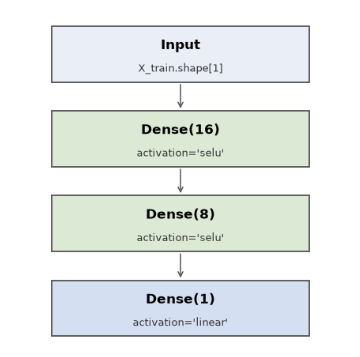

In [42]:
# [13번 문항] 여기에 답안코드를 작성하고 실행하세요.

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation='selu'),
    Dense(8, activation='selu'),
    Dense(1, activation='linear')
])

estop = EarlyStopping(monitor='val_mae', patience=10, restore_best_weights=True)

model.compile(optimizer=RMSprop(), loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, callbacks=[estop])

print(model.count_params())

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 125.6791 - mae: 10.0188 - val_loss: 115.2336 - val_mae: 9.7535
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 110.5287 - mae: 9.3737 - val_loss: 100.2870 - val_mae: 9.0468
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 93.3682 - mae: 8.5421 - val_loss: 82.7296 - val_mae: 8.1077
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 73.9848 - mae: 7.4607 - val_loss: 63.5223 - val_mae: 6.8974
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 54.3054 - mae: 6.1599 - val_loss: 45.0393 - val_mae: 5.5278
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 36.8755 - mae: 4.7786 - val_loss: 29.7805 - val_mae: 4.2376
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 23.9655 - mae: 3.6215 - val_loss: 19.7438 - val_mae: 3.2546
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 16.7788 - mae: 2.9454 - val_loss: 15.0932 - val_mae: 2.8240
Epoch 9/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드를 위에서부터 코드로 옮기세요: 모델 구조 -> 콜백 -> compile -> fit. **개념** `shape[0]` 은 행 수, `shape[1]` 은 열 수입니다. EarlyStopping 의 patience 는 성능이 나아지지 않아도 참고 기다리는 epoch 수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 13번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
model = ____([
    ____(shape=(X_train.shape[____],)),
    ____(____, activation='____'),
    ____(____, activation='____'),
    ____(____, activation='____')
])

estop = ____(monitor='____', patience=____, restore_best_weights=True)
cb_list = [estop]

# ▷ 실행해서 결과 확인 — `compile`, `RMSprop` 사용

# ▷ `history` 에 결과를 저장 — `fit` 사용

# [model] 결과 확인
# ▷ 실행해서 결과 확인 — `count_params` 사용
```
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential>
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/Input>
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense>

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 MAE와(과) 검증 MAE의 변화를 그래프로 시각화하십시오.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 1개의 그래프에 학습 MAE 과 검증 MAE 2가지를 모두 표시하세요
- 그래프의 제목은 'Model MAE' 로, X축 이름은 'Epochs', Y축 이름은 'MAE' 로 표시하세요
- 범례를 'train', 'val' 로 표시하세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `답안14_1`, `답안14_2` 변수에 각각 저장하세요
    - 예시) 답안14_0 = 'data'
- 같은 빈칸 표시가 여러 곳에 있으면 모두 같은 내용이 들어갑니다(정답은 한 번만 입력)
- 배점 : 10점

---

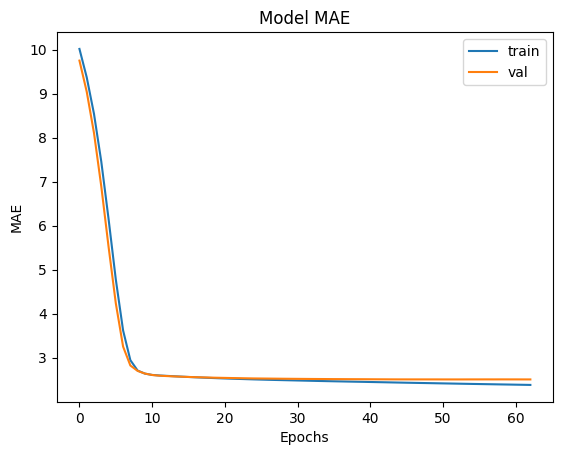

In [43]:
# [14번 문항] 아래 코드의 빈칸을 채우고 실행하세요.

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Model MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend(['train', 'val'])
plt.show()

답안14_1 = 'plot'
답안14_2 = 'title'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 그래프 제목을 지정하는 matplotlib 함수입니다. **개념** plt.title 은 제목, plt.xlabel·ylabel 은 가로·세로축 이름, plt.legend 는 선 이름표입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

빈칸에 들어갈 것은 matplotlib.pyplot(그래프 꾸미기 함수) 쪽 이름입니다. 공식 문서 목록에서 찾아보세요: [matplotlib](https://matplotlib.org/stable/api/pyplot_summary.html)

</details>

<details><summary>힌트 3단계 (코드 구조) - 14번 문항</summary>

코드 구조입니다. `____` 자리에 들어갈 이름은 아래 공식 문서에서 확인하세요(오픈북 사이트).
```python
plt.____(history.history['mae'])
plt.____(history.history['val_mae'])
plt.____('Model MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend(['train', 'val'])
plt.show()

답안14_1 = '____'   # 빈칸 1에 넣은 이름
답안14_2 = '____'   # 빈칸 2에 넣은 이름
```
- 참고 문서: <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html>
- 참고 문서: <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.title.html>

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.

In [46]:
# 전체 자동 채점 — 모든 문항을 푼 뒤 이 셀을 실행하세요. 정답 키는 압축·인코딩되어 있어 내용이 보이지 않습니다.
# (결과 변수 저장형은 지금 노트북에 남아 있는 변수로 채점합니다 — 앞 문항의 변수를 뒤에서 덮어쓰지 마세요)
import base64 as _b64, json as _json, zlib as _zlib
_정답키 = _json.loads(_zlib.decompress(_b64.b64decode("eNqlVs1u4zYQfhVBF1uAIZCSJccFcksOe9oihzaFYRCMRNtCKFIl6W2Mxd4L9NxH6VN1H6JDyY0p2/qJ9xDE5HC+Gc18Hzmrr76Q/k8ennn+ayFy+OlnMmc+rL9QBUux5xwWlSyE0bBOQgTLbMeyV7tcffWNdaLakIxybh03e5HZPc0MkZUppLC7v9sw39bfZt4xZuTEtLHeQ/r5xh8Rkr0VGuxgErRkR78avjbrHa3YmbUOwfd2uYpwBBngeH1yYW9VnUb9H9ZK7kU+3XBJzVRUoaBC70v7i2qqFD1M802oGWeZIbk5VExPJ2JfvjA1Cbxi4+3gmDEKTs28Sesc2BnXzLOWeue+DhIEwcyLAjfNeIFTlKDQFstIbnfCRZy2Chk7hYQU/2BuLf/965/vf/8ZXykozTJW2e9e3YVo/Y6PTsDzYeB5L3Aaxg5wiDA+gSc97SeGlVULOR3Pgca5lwjv+Cc2oLsU2BA5bMgk14TT7LXD19qtq//0+Vfy6cH/MSLVsOPYVB/tptTRPMCrNInRHIWxw6t0Ebu0SvsaJOjN7QHXU6WEPEJ1HbjWvcbjvXd4iRZnvbulAYKOLL+gPcW3xoHSx3OUpMvwzil9nKLUrf1iWHkLglstiM60B/ysDv5VXY9Cj/rRP6u8EJQ/CvtcqB+IEw98BTVsK1XB9PUYd50sfSZQ8SK/jafPxChaCN+l1OWZJkDfmcMInMMFDmfiWiCHRHiJe443Md3j8Ix0qwOK42rhmE8IVWVvQWiVErQYHKFFkiQuX5fDnV5eacSpz3D7JJ1PBUadTd5qotrTAkZje9z4nspi9X1pnx0N9kX40tLxBzx1BhQWW9fdF2xLSkYFoS9a8r1hhCkllZMQ3DlkEPqFwegFf0VJjVTE724zhwJMa/+wooqWZKuKfDURJ289WQftqxVBLSOE1h9GLekbyaG5u3NIePdtP+1ceQNqIYimZcUZPM2Mbi7yhWx7UBvAumI1qiatRFuKQR+EucispZiPgbVb0k4LubrDeFh4GF/Th3PFPjx9+uXxiTw+/0x+u37J4mhEmKg/DMwa85bC0fFKaiLEnRIv4YHhN0q88e27fHewIdWhRzY1RpjBBPF/h6Yt0s3xoofHTExX3NtI5XGvEF4DxumBKW3HCjspTHkQEmITIsS7v/cmD0xodkbtuDvG8RMaoejVhFUy2w3wZsRoj+dnE8b5dO9XXJoOwozDj/rxTWE4awVY/wfGaW/S")).decode("utf-8"))


def _같음(a, b, tol=0):
    try:
        if a is None or b is None:
            return a is None and b is None
        if isinstance(b, str) or isinstance(a, str):
            return str(a).strip().strip("'\"").replace(" ", "").lower() == str(b).strip().strip("'\"").replace(" ", "").lower()
        if isinstance(b, (list, tuple)):
            return len(a) == len(b) and all(_같음(x, y, tol) for x, y in zip(a, b))
        return abs(float(a) - float(b)) <= float(tol) + 1e-9
    except Exception:
        return False


def _검사(g, c):
    if c["t"] in ("ast_call", "ast_import", "ast_count", "src_contains"):
        return _코드검사(g, c)
    try:
        t, obj = c["t"], g.get(c.get("name"))
        if t == "exists":
            return c["name"] in g
        if t == "shape":
            return tuple(obj.shape) == tuple(c["value"])
        if t == "len":
            return len(obj) == c["value"]
        if t == "cols_have":
            return all(x in obj.columns for x in c["cols"])
        if t == "cols_lack":
            return all(x not in obj.columns for x in c["cols"])
        if t == "no_na":
            import pandas as _pd
            return int(_pd.DataFrame(obj).isna().sum().sum()) == 0
        if t == "all_numeric":
            import pandas as _pd
            d = _pd.DataFrame(obj)
            return all(_pd.api.types.is_numeric_dtype(d[x]) or _pd.api.types.is_bool_dtype(d[x]) for x in d.columns if x not in c.get("except", []))
        if t == "expr":
            return _같음(eval(c["expr"], g), c["value"], c.get("tol", 0))
        if t == "attr":
            return _같음(getattr(obj, c["attr"]), c["value"], c.get("tol", 0))
        if t == "has_attr":
            return hasattr(obj, c["attr"])
    except Exception:
        return False
    return False


_채점기록 = {}


def 채점(번호=None):
    """번호를 주면 그 문항만, 없으면 전체 문항을 채점해 점수를 보여 줍니다.
    결과 변수 저장형은 그 문항 바로 뒤의 `채점(번호)` 결과를 기억해 둡니다(뒤 문항이 같은 변수를 바꿀 수 있어서)."""
    g = globals()
    대상 = [k for k in _정답키 if 번호 is None or k["no"] == 번호]
    점수 = 0.0
    for k in 대상:
        if k["kind"] in ("var", "code"):
            지금 = (k["kind"] == "code" or k["var"] in g) and all(_검사(g, c) for c in k["checks"])
            if 번호 is not None:
                _채점기록[k["no"]] = 지금
            ok = _채점기록.get(k["no"], 지금) if 번호 is None else 지금
            무엇 = "작성한 코드" if k["kind"] == "code" else f"변수 `{k['var']}`"
        else:
            v = g.get(k["var"])
            ok = v is not None and any(_같음(v, a, k.get("tol", 0)) for a in k["accept"])
            무엇 = f"`{k['var']}`"
        점수 += k["points"] if ok else 0
        print(f"{'✅' if ok else '❌'} {k['no']}번 ({k['points']:g}점) — {무엇} {'정답' if ok else '다시 확인하세요'}")
    if 번호 is None:
        print(f"\n총점: {점수:g} / {sum(k['points'] for k in _정답키):g}")
        globals()["_최종점수"] = 점수
    return 점수


def _셀기록(g, no=None):
    import ast as _ast
    out = []
    for s in (g.get("In") or g.get("_ih") or []):
        if not isinstance(s, str) or "_정답키" in s:
            continue
        if no is not None and f"[{no}번 문항]" not in s:
            continue
        try:
            body = "\n".join(l for l in s.splitlines() if not l.strip().startswith(("#", "%", "!")))
            out.append((_ast.parse(body), body))
        except SyntaxError:
            pass
    return out


def _코드검사(g, c):
    import ast as _ast
    no = c.get("q")
    def _값(n):
        try:
            return _ast.literal_eval(n)
        except Exception:
            try:
                return _ast.unparse(n)
            except Exception:
                return None
    for tree, _ in _셀기록(g, no):
        for nd in _ast.walk(tree):
            if c["t"] == "ast_call" and isinstance(nd, _ast.Call):
                f = nd.func
                name = f.attr if isinstance(f, _ast.Attribute) else (f.id if isinstance(f, _ast.Name) else None)
                if name != c["func"]:
                    continue
                kws = {k.arg: _값(k.value) for k in nd.keywords if k.arg}
                if all(k in kws and _같음(kws[k], v) for k, v in (c.get("kwargs") or {}).items()) and len(nd.args) >= (c.get("n_pos") or 0):
                    return True
            if c["t"] == "ast_import" and isinstance(nd, (_ast.Import, _ast.ImportFrom)):
                if isinstance(nd, _ast.Import) and any(a.name == c["module"] and (c.get("alias") is None or a.asname == c.get("alias")) for a in nd.names):
                    return True
                if isinstance(nd, _ast.ImportFrom) and c.get("name") and nd.module == c["module"] and any(a.name == c["name"] for a in nd.names):
                    return True
    if c["t"] == "ast_count":
        n = sum(1 for tree, _ in _셀기록(g, no) for nd in _ast.walk(tree) if isinstance(nd, _ast.Call)
                and ((nd.func.attr if isinstance(nd.func, _ast.Attribute) else getattr(nd.func, "id", None)) == c["func"]))
        return c.get("min", 0) <= n <= c.get("max", 10 ** 6)
    if c["t"] == "src_contains":
        src = "\n".join(b for _, b in _셀기록(g, no))
        toks = [c["text"]] if isinstance(c["text"], str) else c["text"]
        return all(t in src for t in toks)
    return False


_점수 = 채점()


✅ 1번 (5점) — 작성한 코드 정답
✅ 2번 (5점) — 변수 `df` 정답
✅ 3번 (5점) — `답안3` 정답
✅ 4번 (5점) — `답안4` 정답
✅ 5번 (6점) — 변수 `df_temp` 정답
✅ 6번 (6점) — 변수 `df_na` 정답
✅ 7번 (2점) — `답안7_1` 정답
✅ 7번 (2점) — `답안7_2` 정답
✅ 7번 (2점) — `답안7_3` 정답
✅ 8번 (6점) — 변수 `X_valid` 정답
✅ 9번 (6점) — `답안9` 정답
✅ 10번 (10점) — 변수 `gs_rf` 정답
✅ 11번 (10점) — `답안11` 정답
✅ 12번 (10점) — `답안12` 정답
✅ 13번 (10점) — 변수 `model` 정답
✅ 14번 (5점) — `답안14_1` 정답
✅ 14번 (5점) — `답안14_2` 정답

총점: 100 / 100
